# Машинное обучение, ФКН ВШЭ

# Практическое задание 8. Обучение без учителя.

## Общая информация
Дата выдачи: 20.09.2026

Мягкий дедлайн: 04.10.2026 23:59 MSK

Жёсткий дедлайн: 11.10.2026 23:59 MSK

## Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи).

Сдавать задание после указанного срока сдачи нельзя.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

## Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:
* Ноутбук homework-practice-08-Username.ipynb

Username — ваша фамилия на латинице

## О задании

В этом задании мы посмотрим на несколько алгоритмов кластеризации и применим их к географическим и текстовым данным. Также мы подробно остановимся на тематическом моделировании текстов, задаче обучения представлений и в каком-то смысле поработаем с semi-supervised learning.



In [1]:
import pandas as pd
import numpy as np


np.random.seed(0xFFFFFFF)

**Задание 0 (1e-100 балла)**. Какие ожидания от курса?

In [2]:
# YOUR CODE HERE (ノಠ益ಠ)ノ彡┻━┻

## Часть 1. Кластеризация автобусных остановок

В этом задании мы сравним разные алгоритмы кластеризации для данных об автобусных остановках Москвы.

**Задание 1.1 (1 балл).** Реализуйте алгоритм спектральной кластеризации, который упоминался на лекции. Для этого разберитесь с кодом шаблона, данного ниже, и допишите недостающую функцию. Напомним, что для графа с матрицей смежности $W = \{w_{ij}\}_{i, j = 1 \dots \ell}$ лапласиан определяется как:

$$
L = D - W,
$$

где $D = \text{diag}(d_1, ..., d_{\ell}), d_i = \sum_{j=1}^{\ell} w_{ij}$.

In [3]:
from sklearn.base import ClusterMixin
from sklearn.cluster import KMeans


class GraphClustering(ClusterMixin):
    def __init__(self, n_clusters=8, n_components=None, **kwargs):
        '''
        Spectral clustering algorithm
        param n_clusters: number of clusters to form
        param n_components: number of eigenvectors to use
        '''

        if n_components is None:
            n_components = n_clusters

        self.n_components = n_components
        self.kmeans = KMeans(n_clusters=n_clusters, **kwargs)

    def fit_predict(self, X, y=None):
        '''
        Perform spectral clustering from graph adjacency matrix
        and return vertex labels.
        param X: (n_samples, n_samples) - graph adjacency matrix
        return: (n_samples, ) - vertex labels
        '''

        eigenvectors = self._generate_eigenvectors(X)
        labels = self.kmeans.fit_predict(eigenvectors[:, 1:])
        return labels

    def _generate_eigenvectors(self, X):
        '''
        Compute eigenvectors for spectral clustering
        param X: (n_samples, n_samples) - graph adjacency matrix
        return: (n_samples, n_components) - eigenvectors
        '''

        # YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
        sumi = X.sum(axis=0)
        diag = np.diag(sumi)

        Laplas = diag - X
        sobs_val, sobs_vect = np.linalg.eigh(Laplas)
        indx = np.argsort(sobs_val)
        sorted_vect = sobs_vect[:, indx]
        
        return sorted_vect[:, :self.n_components +1]
        
        # raise NotImplementedError

Перед тем, как переходить к следующему заданию, протестируйте свое решение.

In [6]:
n_blocks, n_vertices = 10, 1000
block_vertices = n_vertices // n_blocks

X = np.zeros((n_vertices, n_vertices))
for i in range(0, n_vertices, block_vertices):
    X[i:i + block_vertices, i:i + block_vertices] = np.sqrt(i + 1)

graph_clustering = GraphClustering(n_clusters=n_blocks)
labels = graph_clustering.fit_predict(X)

true_labels = np.zeros(n_vertices, dtype=np.int32)
for i in range(0, n_vertices, block_vertices):
    true_labels[i:i + block_vertices] = labels[i]

assert labels.shape == (n_vertices, )
assert np.all(np.bincount(labels) == np.full(n_blocks, block_vertices))
assert np.all(labels == true_labels)

Теперь можем приступить к работе с реальными данными. Скачайте файл с данными об остановках общественного транспорта **в формате .xlsx** по [ссылке](https://disk.yandex.ru/i/J0HlcDXd_KyIeg). Для удобства визуализации мы будем работать только с остановками в ЦАО.

In [7]:
data = pd.read_excel('transport.xlsx')
data = data[data.AdmArea_en == "Czentral`ny'j administrativny'j okrug"]
data = data.reset_index()
data.head()

,index,ID_en,Name_en,Longitude_WGS84_en,Latitude_WGS84_en,Street_en,AdmArea_en,District_en,RouteNumbers_en,StationName_en,Direction_en,Pavilion_en,OperatingOrgName_en,EntryState_en,global_id,geoData
0,278,347,"«2-й Лесной пер.», улица Бутырский Вал (347)",37.586584,55.782106,улица Бутырский Вал,Czentral`ny'j administrativny'j okrug,Tverskoj rajon,АТ18; А12; АТ56; АТ78,2-й Лесной пер.,NaN,да,ГУП «Мосгортранс»,active,889085436,NaN
1,279,349,"«Ул. Сущевский Вал», Новослободская улица (349)",37.590714,55.790630,Новослободская улица,Czentral`ny'j administrativny'j okrug,Tverskoj rajon,АТ47; АМ10; АТ3; АТ56; АТ78,Ул. Сущевский Вал,NaN,да,ГУП «Мосгортранс»,active,889085437,NaN
2,355,479,"«Стадион Лужники (южн.) (пос.)», улица Лужники...",37.565972,55.714265,улица Лужники,Czentral`ny'j administrativny'j okrug,rajon Xamovniki,А64; А216; А809; АС12; А255; АБК; АТ79,Стадион Лужники (южн.) (пос.),NaN,да,ГУП «Мосгортранс»,active,889085549,NaN
3,356,480,"«Спортзал Дружба», Лужнецкая набережная (480)",37.570191,55.712504,Лужнецкая набережная,Czentral`ny'j administrativny'j okrug,rajon Xamovniki,А64; А216; А809; АС12; А255; АБК; АТ79,Спортзал Дружба,NaN,да,ГУП «Мосгортранс»,active,889085550,NaN
4,357,481,"«Лужнецкая наб.», Лужнецкая набережная (481)",37.574559,55.713770,Лужнецкая набережная,Czentral`ny'j administrativny'j okrug,rajon Xamovniki,А64; А216; А809; АС12; А255; АБК; АТ79,Лужнецкая наб.,NaN,да,ГУП «Мосгортранс»,active,889085551,NaN


Воспользуемся библиотекой `folium` для визуализации данных.

In [8]:
import folium

map = folium.Map([55.75215, 37.61819], zoom_start=12)
for id, row in data.iterrows():
    folium.Circle([row.Latitude_WGS84_en, row.Longitude_WGS84_en],
                  radius=10).add_to(map)
map

**Задание 1.2 (1 балл).** Попробуем построить граф, в котором вершинами будут остановки. Как вы уже могли заметить, для каждой остановки указаны номера маршрутов, проходящих через неё. Логично соединить ребрами соседние остановки каждого маршрута. Однако мы не знаем, в каком порядке автобусы объезжают остановки. Но мы можем применить эвристический алгоритм, который восстановит нам порядок маршрутов:

* Для каждого маршрута выделим список всех остановок, через которые он проходит.
* Выберем начальную остановку маршрута как точку, наиболее удаленную от всех остальных остановок этого маршрута.
* Каждую следующую точку маршрута будем выбирать как самую близкую из оставшихся точек (не включенных в маршрут ранее).

Фактически, у нас получается жадное решение задачи коммивояжера. Когда мы отсортировали маршруты, можем построить по ним граф. Будем строить его по таким правилам:

* Между двумя остановками будет ребро, если они являются соседними хотя бы на одном маршруте. Вес ребра равен числу маршрутов, на которых остановки являются соседними.
* В графе не будет петель (то есть у матрицы смежности будет нулевая диагональ).

Реализуйте предложенный способ построения графа. Для этого рекомендуется воспользоваться шаблонами, приведенными ниже.

In [9]:
def get_routes(data):
    '''
    Accumulate routes from raw data
    param data: pd.DataFrame - public transport stops data
    return: dict - unsorted stops ids for each route,
                   e.g. routes['A1'] = [356, 641, 190]
    '''

    # YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
    # data["Name_en"],data["ID_en"] RouteNumbers_en
    dick = dict()
    for idx, row in data.iterrows():
        for num in str(row["RouteNumbers_en"]).split('; '):
            if num in dick:
                dick[num].append(idx)
            else:
                dick[num] = [idx]
    
    return dick
    
    # raise NotImplementedError


def sort_routes(data, routes):
    '''
    Sort routes according to the proposed algorithm
    param data: pd.DataFrame - public transport stops data
    param routes: dict - unsorted stops ids for each route
    return: dict - sorted stops ids for each route
    '''

    # YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
    sorted_routes = dict()

    for key, values in routes.items():
        if len(values)<=2:
            sorted_routes[key] = values
            
        else:
            coords = data.loc[values, ['Latitude_WGS84_en', 'Longitude_WGS84_en']].values
            distance = np.linalg.norm(coords[:, None] - coords, axis=-1)
            
            sumi = distance.sum(axis=0)
            start_idx = np.argmax(sumi)
            
            unvisited = set(range(len(values)))
            unvisited.remove(start_idx)
            
            sorted_route = [values[start_idx]]
            current_idx = start_idx

            while unvisited:
                nearest_idx = min(unvisited, key = lambda idx: distance[current_idx, idx])
                sorted_route.append(values[nearest_idx])

                unvisited.remove(nearest_idx)
                current_idx = nearest_idx

            sorted_routes[key] = sorted_route

    return sorted_routes
                
    
    # raise NotImplementedError


def get_adjacency_matrix(data, sorted_routes):
    '''
    Compute adjacency matrix for sorted routes
    param data: pd.DataFrame - public transport stops data
    param sorted_routes: dict - sorted stops ids for each route
    return: (n_samples, n_samples) - graph adjacency matrix
    '''

    # YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
    N = len(data)
    zero_matrx = np.zeros((N,N))

    for key, values in sorted_routes.items():
        for i in range(len(values)-1):
            
            zero_matrx[values[i],values[i+1]] +=1
            zero_matrx[values[i+1],values[i]] +=1

    return zero_matrx
            
    # raise NotImplementedError

In [10]:
routes = get_routes(data)
sorted_routes = sort_routes(data, routes)
adjacency_matrix = get_adjacency_matrix(data, sorted_routes)

Проверим, что маршруты получились адекватными. Для этого нарисуем их на карте.

In [11]:
map = folium.Map([55.75215, 37.61819], zoom_start=12)
for route_id in np.random.choice(list(sorted_routes.keys()), size=5):
    coords = data.loc[
        sorted_routes[route_id],
        ['Latitude_WGS84_en', 'Longitude_WGS84_en']
    ].values.tolist()
    folium.vector_layers.PolyLine(coords).add_to(map)

map

**Задание 1.3 (0 баллов)**. Реализуйте функцию `draw_clustered_map`, которая рисует карту центра Москвы с кластерами остановок, раскрашенными в разные цвета.

In [12]:
def draw_clustered_map(data, labels):
    '''
    Create map with coloured clusters
    param data: pd.DataFrame - public transport stops data
    param labels: (n_samples, ) - cluster labels for each stop
    return: folium.Map - map with coloured clusters
    '''
    m = folium.Map([55.75215, 37.61819], zoom_start=12)
    palette = [
        'red', 'blue', 'green', 'purple', 'orange', 
        'darkred', 'lightred', 'beige', 'darkblue', 
        'darkgreen', 'cadetblue', 'darkpurple', 'pink', 
        'lightblue', 'lightgreen'
    ]
    
    for i in range(len(data)):
        lat = data.iloc[i]['Latitude_WGS84_en']
        lon = data.iloc[i]['Longitude_WGS84_en']
        cluster = labels[i]

        if cluster == -1:
            point_color = 'black'
        else:
            point_color = palette[cluster % len(palette)]
            
        folium.CircleMarker(
            location=[lat, lon],
            radius=4,
            color=point_color,
            fill=True,
            fill_color=point_color,
            fill_opacity=0.8
        ).add_to(m)
        
    return m
    # YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
    # raise NotImplementedError

**Задание 1.4 (1.5 балла)**. Примените алгоритмы кластеризации и подберите гиперпараметры так, чтобы кластеры получились осмысленными (нет такого, что все принадлежит одному кластеру или большая часть точек это шум):
- `sklearn.clustering.KMeans` - `n_clusters`
- `sklearn.clustering.DBSCAN` - `eps`
- ваш `SpectralClustering` - `n_clusters` и `n_components`

Для ряда алгоритмов, в частности DBSCAN, подобрать оптимальные параметры может быть ой, как непросто. Чтобы помочь сохранить нервные клетки рекомендуется пользоваться метриками Intrinsic Evaluation для кластеризации. Для каждого алгоритма скорее всего придется брать разные метрики, а может быть оптимизировать сразу несколько.

Ваша задача - выбрать подходящую метрику, можно взять что-то из списка ниже, можно спросить у гугла. Применить GridSearch, `optuna` или `hyperopt` и желательно завернуть отбор параметров в функцию, пригодится далее

1. $
   \text{Calinski-Harabasz Index} \in [0, \inf] = \frac{\sum_{i=1}^k BCSS_i/(k-1)}{\sum_{i=1}^k WCSS_i/(n-k)} = \frac{\sum_{i=1}^k n_i \| \mathbf{c}_i - \mathbf{c} \|^2/(k-1)}{\sum_{i=1}^k \sum_{\mathbf{x} \in C_i} \|\mathbf{x} - \mathbf{c}_i\|^2/(n-k)} \rightarrow max
   $
   - Отношение 1) расстояния от центра кластера до центра всех данных к 2) расстоянию от центра кластера до точки
   - Чем однороднее и дальше друг от друга кластеры, тем лучше
2. $
   \text{Silhouette Score} \in [0, 1] = \sum_i \frac{b_i - a_i}{\max(a_i, b_i)} \rightarrow max
   $
   - $a_i$ - среднее расстояние до точек внутри своего кластера
   - $b_i$ - среднее расстояние до точек из ближайшего кластера
   - Если в своем кластере точки близко - кластер плотный, идеальный вариант, скор равен 1, если свой кластер совпадает с соседним - кластеры неразделимы, скор равен нулю
   - Чем однороднее и разделимее кластеры, тем лучше
3. $\text{Davies-Bouldin Index} \in [0, inf] = \frac{1}{k} \sum_{i=1}^{k} \max_{j \neq i} \left( \frac{WCSS_i + WCSS_j}{d(c_i, c_j)} \right) \rightarrow min $
   - Отношение внутрикластерных расстояний к межкластерному расстоянию между двумя центрами
   - Если кластеры далеко друг от друга, но при этом однородные, скор наименьший
3. $\text{Elbow Method}$ - последовательное сравнение $WCSS$ из пункта 1 для разного числа параметров. Если уменьшение меньше определенного порога - останавливаемся, считаем это значение оптимальным

In [17]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from sklearn.preprocessing import StandardScaler

def clustering_objective():
    # YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿

    coords = data[['Latitude_WGS84_en', 'Longitude_WGS84_en']].values
    scaler = StandardScaler()
    coords_scaled = scaler.fit_transform(coords)

    best_labels = {}

    kmeans_metrics = {}
    for n_clusters in range(2, 15):
        kmeans = KMeans(n_clusters=n_clusters)
        labels = kmeans.fit_predict(coords_scaled)

        score = calinski_harabasz_score(coords_scaled, labels)
        kmeans_metrics[n_clusters] = score

    best_k = max(kmeans_metrics, key=kmeans_metrics.get)
    best_labels['kmeans'] = KMeans(n_clusters=best_k).fit_predict(coords_scaled)


    dbscan_metrics = {}
    for eps in np.arange(0.1, 1.1, 0.1):
        dbscan = DBSCAN(eps=eps, min_samples=4)
        labels = dbscan.fit_predict(coords_scaled)
        
        if len(set(labels)) > 1 and len(set(labels)) < len(coords_scaled):
            score = silhouette_score(coords_scaled, labels)
            dbscan_metrics[eps] = score

    if dbscan_metrics:
        best_eps = max(dbscan_metrics, key=dbscan_metrics.get)
        best_labels['dbscan'] = DBSCAN(eps=best_eps, min_samples=4).fit_predict(coords_scaled)
    else:
        best_labels['dbscan'] = np.zeros(len(coords_scaled))

    graph_metrics = {}
    for n_clusters in range(2, 10):
        for n_components in range(2, 10):
            gc = GraphClustering(n_clusters=n_clusters, n_components=n_components)
            labels = gc.fit_predict(adjacency_matrix)
            
            if len(set(labels)) > 1:
                score = calinski_harabasz_score(coords_scaled, labels)
                graph_metrics[(n_clusters, n_components)] = score

    best_g_params = max(graph_metrics, key=graph_metrics.get)
    best_gc = GraphClustering(n_clusters=best_g_params[0], n_components=best_g_params[1])
    best_labels['graph'] = best_gc.fit_predict(adjacency_matrix)


    return best_labels

best_cluster_labels = clustering_objective()

C:\Users\danii\PycharmProjects\pythonProject9\.venv\Lib\site-packages\sklearn\base.py:1336: ConvergenceWarning: Number of distinct clusters (5) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
C:\Users\danii\PycharmProjects\pythonProject9\.venv\Lib\site-packages\sklearn\base.py:1336: ConvergenceWarning: Number of distinct clusters (6) found smaller than n_clusters (7). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
C:\Users\danii\PycharmProjects\pythonProject9\.venv\Lib\site-packages\sklearn\base.py:1336: ConvergenceWarning: Number of distinct clusters (7) found smaller than n_clusters (8). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
C:\Users\danii\PycharmProjects\pythonProject9\.venv\Lib\site-packages\sklearn\base.py:1336: ConvergenceWarning: Number of distinct clusters (7) found smaller than n_clusters (8). Possibly due to duplica

Визуализируйте результат кластеризации с помощью функции `draw_clustered_map`.

In [18]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
draw_clustered_map(data, best_cluster_labels['kmeans'])

In [19]:
draw_clustered_map(data, best_cluster_labels['dbscan'])

In [20]:
draw_clustered_map(data, best_cluster_labels['graph'])

**Вопрос:** Чем отличаются разбиения на кластеры, получаемые разными алгоритмами? Какие плюсы и минусы есть у каждого алгоритма? Какой алгоритм кажется вам наиболее подходящим для кластеризации остановок?

**Ответ:** k-means сделал всё понятнее всего и поделил центр на аккуратные небольшие зоны. он просто собрал близкие точки вместе. dbscan наоборот слепил почти все остановки в одно огромное красное пятно и нашел только пару черных точек шума по краям. так вышло из-за слишком высокой плотности остановок в центре города. спектральная кластеризация тоже выдала один сплошно1й кусок и отделила от него лишь пару остановок. автобусная сеть очень сильно связана маршрутами и алгоритму было сложно нормально разрезать этот граф. в итоге визуально самым нормальным и похожим на адекватный результат получился k-means

## Часть 2. Тематическое моделирование текстов

В этой части мы познакомимся с одной из самых популярных задач обучения без учителя &mdash; с задачей тематического моделирования текстов. Допустим, нам доступна некоторая коллекция документов без разметки, и мы хотим автоматически выделить несколько тем, которые встречаются в документах, а также присвоить каждому документу одну (или несколько) тем. Фактически, мы будем решать задачу, похожую на кластеризацию текстов: отличие в том, что нас будет интересовать не только разбиение текстов на группы, но и выделение ключевых слов, определяющих каждую тему.

Мы будем работать с новостными статьями BBC за 2004-2005 годы. Скачайте данные по [ссылке](https://www.kaggle.com/hgultekin/bbcnewsarchive).

In [21]:
data = pd.read_csv('bbc-news-data.csv', sep='\t')
data.sample(5)

,category,filename,title,content
731,entertainment,222.txt,School tribute for TV host Carson,"More than 1,000 people turned out on Sunday t..."
2018,tech,195.txt,Ban hits Half-Life 2 pirates hard,"About 20,000 people have been banned from pla..."
1032,politics,137.txt,Defiant hunts put ban to the test,Thousands of hunt supporters have been out on...
516,entertainment,007.txt,Levy tipped for Whitbread prize,Novelist Andrea Levy is favourite to win the ...
199,business,200.txt,Cuba winds back economic clock,Fidel Castro's decision to ban all cash trans...


Как вы могли заметить, данные уже содержат разметку по тематике (колонка category). В этой части мы забудем, что она есть, и будем работать только с текстовыми данными. Проведем предобработку текста, состоящую из следующих пунктов:

* Объединим заголовок и содержание статьи в одно поле.
* Приведем текст к нижнему регистру, разобьем его на токены.
* Оставим только буквенные слова (удалив, таким образом, пунктуацию и числа).
* Применим лемматизацию.
* Удалим стоп-слова.


In [22]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

In [23]:
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('punkt_tab')
nltk.download('stopwords')

stop_words = set(stopwords.words('english') + ['ha', 'wa', 'say', 'said'])
lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\danii\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\danii\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\danii\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\danii\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [24]:
def preprocess(text):
    text = list(filter(str.isalpha, word_tokenize(text.lower())))
    text = list(lemmatizer.lemmatize(word) for word in text)
    text = list(word for word in text if word not in stop_words)
    return ' '.join(text)

In [25]:
data['raw_text'] = data.apply(lambda row: row.title + row.content, axis=1)
data['text'] = data.apply(lambda row: preprocess(row.raw_text), axis=1)

Для визуализации частот слов в текстах мы будем использовать [облака тегов](https://en.wikipedia.org/wiki/Tag_cloud).

In [26]:
from wordcloud import WordCloud

def draw_wordcloud(texts, max_words=1000, width=1000, height=500):
    wordcloud = WordCloud(background_color='white', max_words=max_words,
                          width=width, height=height)

    joint_texts = ' '.join(list(texts))
    wordcloud.generate(joint_texts)
    return wordcloud.to_image()

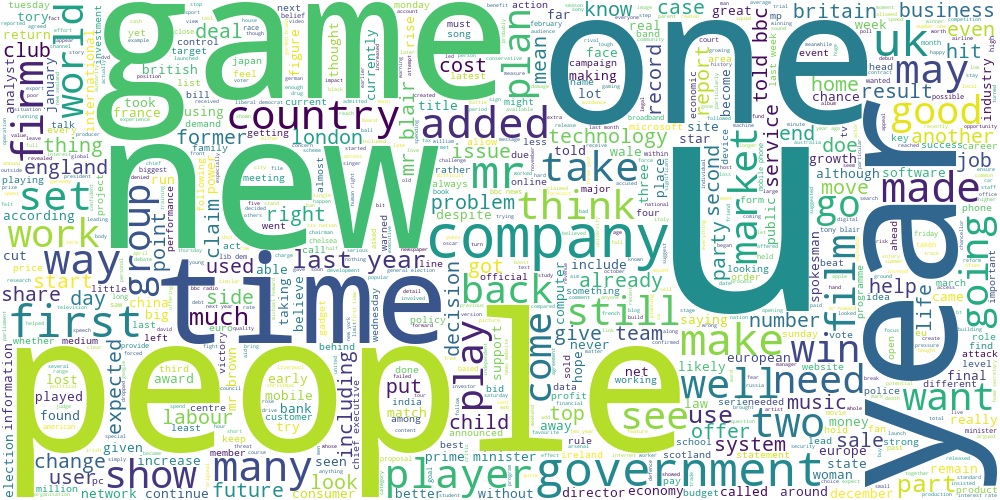

In [27]:
draw_wordcloud(data.text)

**Задание 2.1 (1 балл).** Обучите алгоритм K-Means на tf-idf представлениях текстов. При обучении tf-idf векторайзера рекомендуется отбрасывать редко встречающиеся слова, а также воздержитесь от использования N-грамм. Возьмите не очень большое число кластеров, чтобы было удобно интерпретировать получившиеся темы (например, `n_clusters` = 8). Постройте облака тегов для текстов из разных кластеров.

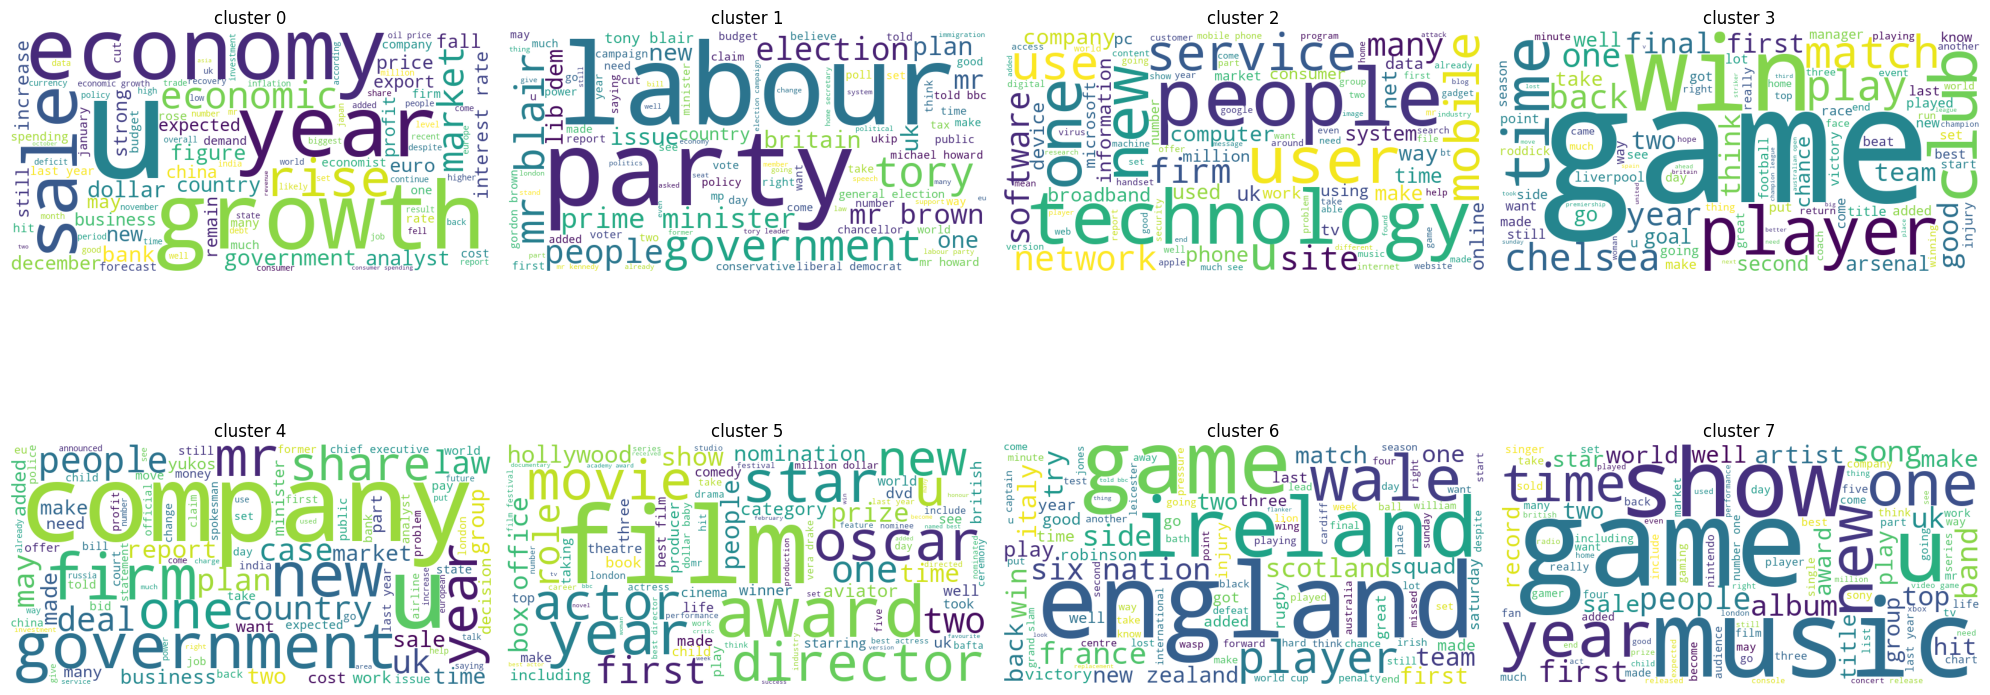

In [43]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt

vectorizer = TfidfVectorizer(min_df=5, max_df=0.9)
X_tfidf = vectorizer.fit_transform(data['text'])

n_clusters = 8
kmeans = KMeans(n_clusters=n_clusters)
data['cluster'] = kmeans.fit_predict(X_tfidf)

plt.figure(figsize=(20, 10))

for cluster_idx in range(n_clusters):
    cluster_texts = data[data['cluster'] == cluster_idx]['text']
    
    wordcloud_img = draw_wordcloud(cluster_texts, max_words=100, width=800, height=400)
    
    plt.subplot(2, 4, cluster_idx + 1)
    plt.imshow(wordcloud_img)
    plt.title(f'cluster {cluster_idx}')
    plt.axis('off')

plt.tight_layout()
plt.show()

Получились ли темы интерпретируемыми? Попробуйте озаглавить каждую тему.

**Ответ:**

да, темы получились очень интерпретируемыми

0 это технологии и гаджеты

1 музыка

2 кино и фильмы

3 какой-то мировой чемпионат спортивный, по типу олимпиады

4 политика и выборы

5 софт и интернет

6 бизнес и экономика

7 киберспорт в англии


**Задание 2.2 (0.5 балла).** Попробуем другой способ выделить ключевые слова для каждой темы. Помимо непосредственного разбиения объектов алгоритм K-Means получает центр каждого кластера. Попробуйте взять центры кластеров и посмотреть на слова, для которых значения соответствующих им признаков максимальны.

In [44]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
feature_names = vectorizer.get_feature_names_out()
n_top_words = 15

for cluster_idx, cluster_center in enumerate(kmeans.cluster_centers_):
    print(f"тема #{cluster_idx}:")

    top_words_indices = cluster_center.argsort()[:-n_top_words - 1:-1]
    top_words = [feature_names[i] for i in top_words_indices]
    
    print(" ".join(top_words))
    print("-" * 50)

тема #0:
growth economy rate price economic year bank dollar sale market rise figure quarter deficit profit
--------------------------------------------------
тема #1:
mr labour election party blair tory brown tax howard would minister government chancellor prime conservative
--------------------------------------------------
тема #2:
mobile phone people technology user service computer software net digital site broadband network music system
--------------------------------------------------
тема #3:
game champion club win chelsea player match cup play season arsenal final world open second
--------------------------------------------------
тема #4:
mr company firm government would share year law deal new yukos court country market bank
--------------------------------------------------
тема #5:
film award best oscar actor star festival actress director movie comedy hollywood year aviator nomination
--------------------------------------------------
тема #6:
england rugby wale ireland

Согласуются ли полученные слова с облаками тегов из прошлого задания?

**Ответ:**
да, полученные слова полностью согласуются с облаками тегов. центры кластеров k-means в векторном пространстве tf-idf отражают слова с наибольшими средними весами для каждой группы. списки топ-слов для каждой темы по большей части повторяют самые крупные слова с картинок из предыдущего пункта мобильные устройства, музыка, кино, легкая атлетика, политика, софт, экономика и командный спорт


**Задание 2.3 (1.5 балла).** В первой части мы сравнили три разных алгоритма кластеризации на географических данных. Проделаем то же самое для текстовых данных (в качестве признакого описания снова используем tf-idf). Получите три разбиения на кластеры с помощью алгоритмов K-Means, DBSCAN и спектральной кластеризации (на этот раз воспользуйтесь реализацией из `sklearn`). Для K-Means и спектральной кластеризации возьмите одинаковое небольшое число кластеров, подберите параметр `eps` метода DBSCAN так, чтобы получить приблизительно такое же число кластеров (подумайте, как это можно сделать)

Далее, обучите двухмерные t-SNE представления над tf-idf признаками текстов. Визуализируйте эти представления для каждого алгоритма, раскрасив каждый кластер своим цветом. Лучше всего расположить визуализации на одном графике на трех разных сабплотах. Не забудьте, что DBSCAN помечает некоторые точки как шумовые (можно раскрасить их в отдельный цвет).

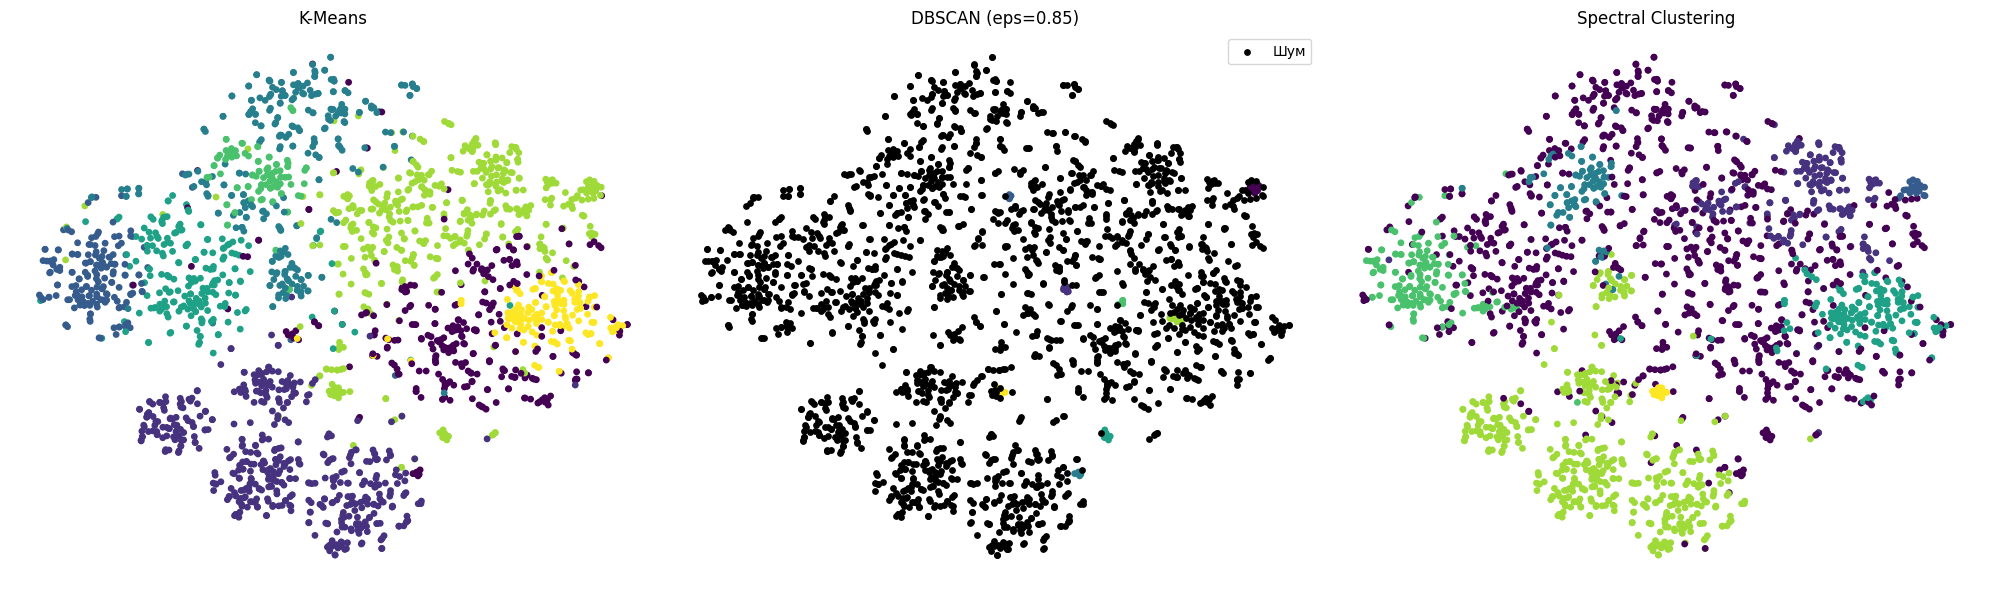

In [50]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
from sklearn.cluster import SpectralClustering
from sklearn.manifold import TSNE

n_clusters = 8

kmeans_labels = KMeans(n_clusters=n_clusters).fit_predict(X_tfidf)
spectral_labels = SpectralClustering(n_clusters=n_clusters).fit_predict(X_tfidf)

best_eps = 0.5
dbscan_labels = None
for eps in np.arange(0.1, 2.0, 0.05):
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_tfidf)
    n_found_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    if n_found_clusters == n_clusters:
        best_eps = eps
        dbscan_labels = labels
        break

if dbscan_labels is None:
    dbscan_labels = DBSCAN(eps=best_eps, min_samples=5).fit_predict(X_tfidf)

X_tsne = TSNE(n_components=2).fit_transform(X_tfidf)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_labels, s=15)
axes[0].set_title('K-Means')
axes[0].axis('off')

noise = dbscan_labels == -1
axes[1].scatter(X_tsne[~noise, 0], X_tsne[~noise, 1], c=dbscan_labels[~noise], s=15)
axes[1].scatter(X_tsne[noise, 0], X_tsne[noise, 1], c='black', s=15, label='Шум')
axes[1].set_title(f'DBSCAN (eps={best_eps:.2f})')
axes[1].legend()
axes[1].axis('off')

axes[2].scatter(X_tsne[:, 0], X_tsne[:, 1], c=spectral_labels, s=15)
axes[2].set_title('Spectral Clustering')
axes[2].axis('off')

plt.tight_layout()
plt.show()

Прокомментируйте получившиеся результаты. Какой баланс кластеров получился у разных методов? Соотносятся ли визуализации для текстов с визуализациями для географических данных?

**Ответ:**
у k-means получилось хорошо, алгоритм разбил тексты на примерно равные группы. dbscan не справился и записал почти все точки в шум, закрасив их черным цветом. спектральная кластеризация собрала один огромный фиолетовый кластер и несколько неболльших групп

результаты похожи на визуализацию географии. алгоритм k-means снова показал самое адекватное разделение, а методы на основе плотности и графов опять слили все данные в одну гигантскую кучу или посчитали их шумом, но спектральная класстеризация в этот раз показала себя лучше

**Задание 2.4 (1.5 балла).** Обучите модель латентного размещения Дирихле. Не забудьте, что она работает с мешком слов, а не с tf-idf признаками. Придумайте, как превратить распределение тем для текста в номер его кластера. Возьмите параметр `n_components` в 2-3 раза больше, чем число кластеров для K-Means.

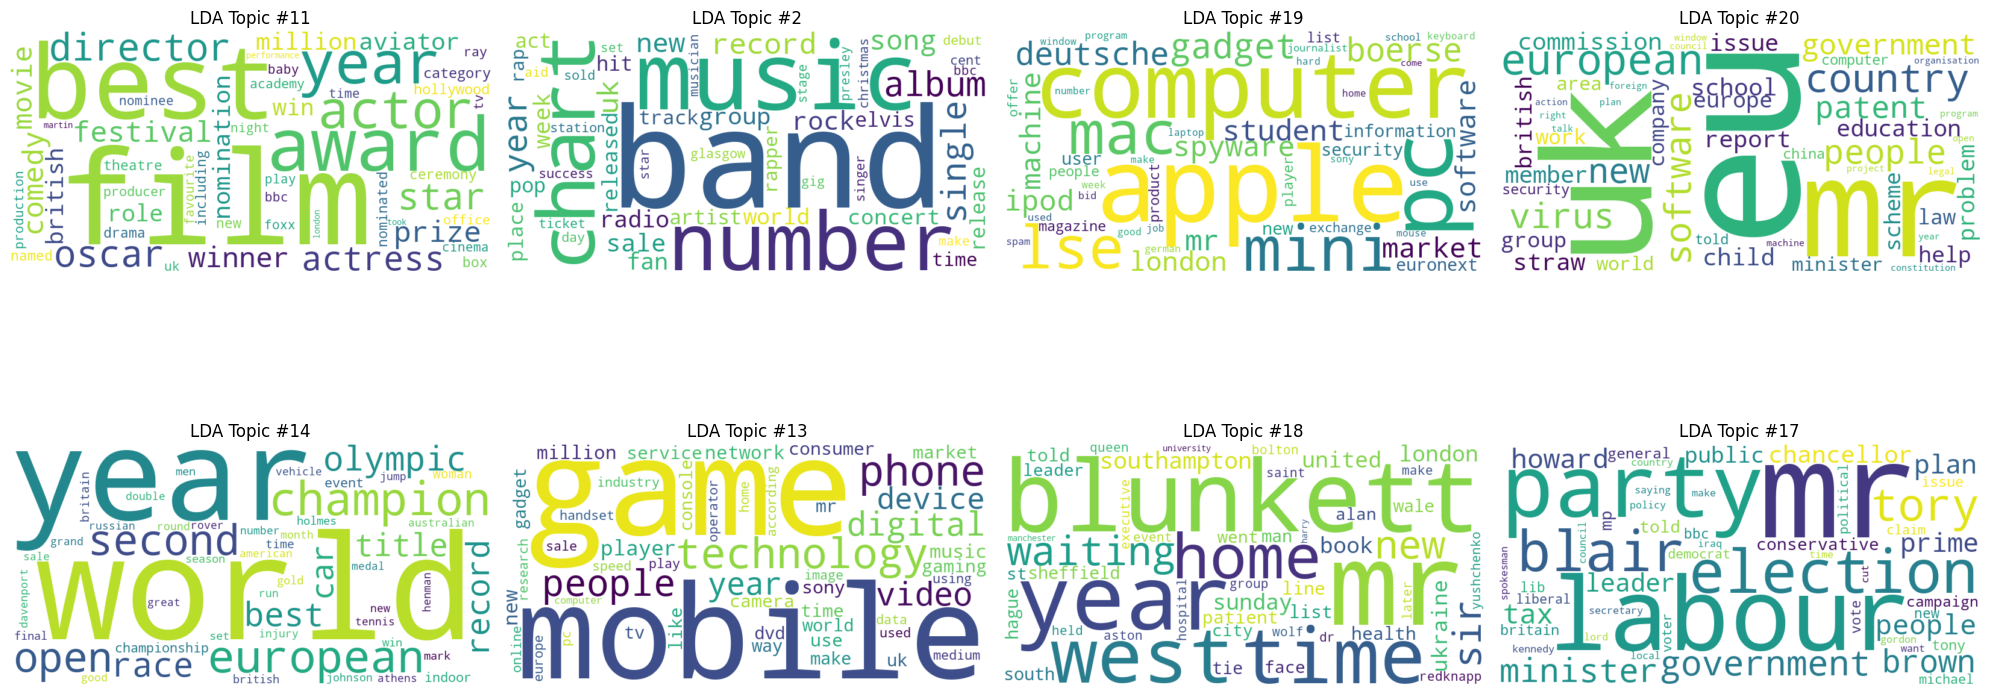

In [52]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

vectorizer_bow = CountVectorizer(min_df=5, max_df=0.9, stop_words='english')
X_bow = vectorizer_bow.fit_transform(data['text'])

n_topics = 24
lda = LatentDirichletAllocation(n_components=n_topics)
X_topics = lda.fit_transform(X_bow)

lda_labels = KMeans(n_clusters=8).fit_predict(X_topics)
data['lda_cluster'] = lda_labels

feature_names = vectorizer_bow.get_feature_names_out()
plt.figure(figsize=(20, 10))
selected_topics = np.random.choice(range(n_topics), 8, replace=False)

for i, topic_idx in enumerate(selected_topics):
    topic = lda.components_[topic_idx]
    
    top_words_indices = topic.argsort()[:-51:-1]
    top_words_dict = {feature_names[j]: topic[j] for j in top_words_indices}
    
    wc = WordCloud(background_color='white', width=800, height=400).generate_from_frequencies(top_words_dict)
    
    plt.subplot(2, 4, i + 1)
    plt.imshow(wc, interpolation='bilinear')
    plt.title(f'LDA Topic #{topic_idx}')
    plt.axis('off')

plt.tight_layout()
plt.show()

Получились ли темы более узкими от такого нововведения? Постройте облака тегов для нескольких наиболее удачных тем.

**Ответ:**
да, темы и вправду стали более узкими. большой кластер технологий разбился на отдельные мелкие темы про мобильные телефоны, интернет с поисковиками  и компьютерные игры. вместо общего спорта появилась конкретная тема про футбольный клуб (емае, я думал это киберспорт). также выделилась отдельная криминальная тема про суды и полицию, которая раньше сливалась с политикой

## Часть 3. Transfer learning и Self-Supervised Learning для задачи классификации текстов

**Задание 3.1 (0.5 балла).** Вспомним, что у нас есть разметка для тематик статей. Попробуем обучить классификатор поверх unsupervised-представлений для текстов. Рассмотрите три модели:

* Логистическая регрессия на tf-idf признаках
* K-Means на tf-idf признаках + логистическая регрессия на расстояниях до центров кластеров
* Латентное размещение Дирихле + логистическая регрессия на вероятностях тем

Разделите выборку на обучающую и тестовую, замерьте accuracy на обоих выборках для всех трех моделей. Параметры всех моделей возьмите равными значениям по умолчанию.

In [38]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(data['text'], data['category'], test_size=0.3)

tfidf_vec = TfidfVectorizer(min_df=5, max_df=0.9)
X_train_tfidf = tfidf_vec.fit_transform(X_train)
X_test_tfidf = tfidf_vec.transform(X_test)

lr_tfidf = LogisticRegression()
lr_tfidf.fit(X_train_tfidf, y_train)
print(f"TF-IDF - Train: {accuracy_score(y_train, lr_tfidf.predict(X_train_tfidf)):.4f}, Test: {accuracy_score(y_test, lr_tfidf.predict(X_test_tfidf)):.4f}")

kmeans = KMeans(n_clusters=8)
X_train_dist = kmeans.fit_transform(X_train_tfidf)
X_test_dist = kmeans.transform(X_test_tfidf)

lr_kmeans = LogisticRegression()
lr_kmeans.fit(X_train_dist, y_train)
print(f"K-Means - Train: {accuracy_score(y_train, lr_kmeans.predict(X_train_dist)):.4f}, Test: {accuracy_score(y_test, lr_kmeans.predict(X_test_dist)):.4f}")

bow_vec = CountVectorizer(min_df=5, max_df=0.9)
X_train_bow = bow_vec.fit_transform(X_train)
X_test_bow = bow_vec.transform(X_test)

lda = LatentDirichletAllocation(n_components=24)
X_train_lda = lda.fit_transform(X_train_bow)
X_test_lda = lda.transform(X_test_bow)

lr_lda = LogisticRegression()
lr_lda.fit(X_train_lda, y_train)
print(f"LDA - train: {accuracy_score(y_train, lr_lda.predict(X_train_lda)):.4f}, Test: {accuracy_score(y_test, lr_lda.predict(X_test_lda)):.4f}")

TF-IDF - Train: 0.9968, Test: 0.9790
K-Means - Train: 0.8137, Test: 0.8129
LDA - train: 0.9371, Test: 0.9581


У какой модели получилось лучшее качество? С чем это связано?

**Ответ:**
лучшее качество получилось у обычной логистической регрессии на tf-idf. это ожидаемо, потому что матрицы tf-idf сохраняют максимум исходной информации о каждом слове в текстах. алгоритмы k-means и lda сильно сжимают данные до нескольких тем или расстояний до центров кластеров. при таком сильном сжатии теряется много мелких но важных деталей, поэтому их точность предсказаний получилась ниже

**Задание 3.2 (1.5 балла).** Теперь просимулируем ситуацию слабой разметки, которая часто встречается в реальных данных. Разделим обучающую выборку в пропорции 5:65:30. Будем называть части, соответственно, размеченный трейн, неразмеченный трейн и валидация.

Все unsupervised-алгоритмы (векторайзеры и алгоритмы кластеризации) запускайте на всем трейне целиком (размеченном и неразмеченном, суммарно 70%), а итоговый классификатор обучайте только на размеченном трейне (5%). Подберите гиперпараметры моделей по качеству на валидации (30%), а затем оцените качество на тестовой выборке (которая осталась от прошлого задания). Не скромничайте при подборе числа кластеров, сейчас нас интересует не интерпретируемое разбиение выборки, а итоговое качество классификации.

In [39]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿

X_train_lab, X_temp, y_train_lab, y_temp = train_test_split(X_train, y_train, train_size=0.05)
X_train_unlab, X_val, y_train_unlab, y_val = train_test_split(X_temp, y_temp, train_size=65/95)

X_train_unsup = pd.concat([X_train_lab, X_train_unlab])

tfidf_vec = TfidfVectorizer(min_df=5, max_df=0.9)
tfidf_vec.fit(X_train_unsup)

X_train_lab_tfidf = tfidf_vec.transform(X_train_lab)
X_val_tfidf = tfidf_vec.transform(X_val)
X_test_tfidf = tfidf_vec.transform(X_test)
X_train_unsup_tfidf = tfidf_vec.transform(X_train_unsup)

lr_tfidf = LogisticRegression(max_iter=500)
lr_tfidf.fit(X_train_lab_tfidf, y_train_lab)

best_acc_kmeans, best_k = 0, 2
for k in [8, 16, 32, 64]:
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(X_train_unsup_tfidf)
    
    lr = LogisticRegression(max_iter=500)
    lr.fit(kmeans.transform(X_train_lab_tfidf), y_train_lab)
    acc = accuracy_score(y_val, lr.predict(kmeans.transform(X_val_tfidf)))
    
    if acc > best_acc_kmeans:
        best_acc_kmeans, best_k = acc, k

kmeans = KMeans(n_clusters=best_k)
kmeans.fit(X_train_unsup_tfidf)
lr_kmeans = LogisticRegression(max_iter=500)
lr_kmeans.fit(kmeans.transform(X_train_lab_tfidf), y_train_lab)

bow_vec = CountVectorizer(min_df=5, max_df=0.9)
bow_vec.fit(X_train_unsup)

X_train_unsup_bow = bow_vec.transform(X_train_unsup)
X_train_lab_bow = bow_vec.transform(X_train_lab)
X_val_bow = bow_vec.transform(X_val)
X_test_bow = bow_vec.transform(X_test)

best_acc_lda, best_comp = 0, 2
for comp in [8, 16, 24, 32]:
    lda = LatentDirichletAllocation(n_components=comp)
    lda.fit(X_train_unsup_bow)
    
    lr = LogisticRegression(max_iter=500)
    lr.fit(lda.transform(X_train_lab_bow), y_train_lab)
    acc = accuracy_score(y_val, lr.predict(lda.transform(X_val_bow)))
    
    if acc > best_acc_lda:
        best_acc_lda, best_comp = acc, comp

lda = LatentDirichletAllocation(n_components=best_comp)
lda.fit(X_train_unsup_bow)
lr_lda = LogisticRegression(max_iter=500)
lr_lda.fit(lda.transform(X_train_lab_bow), y_train_lab)

print(f"TF-IDF test: {accuracy_score(y_test, lr_tfidf.predict(X_test_tfidf)):.4f}")
print(f"K-Means k={best_k} test: {accuracy_score(y_test, lr_kmeans.predict(kmeans.transform(X_test_tfidf))):.4f}")
print(f"LDA comp={best_comp} test: {accuracy_score(y_test, lr_lda.predict(lda.transform(X_test_bow))):.4f}")

TF-IDF test: 0.7395
K-Means k=64 test: 0.6871
LDA comp=24 test: 0.9356


Как изменились результаты по сравнению с обучением на полной разметке? Сделайте выводы.

**Ответ:**
tf-idf сильно просел из-за нехватки данных. lda почти не потеряла в качестве и победила. она вытянула хорошие темы из всего массива неразмеченных текстов, поэтому финальному классификатору хватило всего 5 процентов разметки для крутого результата.

то есть при дефиците размеченных данных предварительное обучение без учителя спасает результат

## Бонус

**Задание 4 (0.5 балла)**. Разберитесь с semi-supervised методами, которые реализованы в `sklearn` и примените их к заданию 3.2. Получилось ли добиться лучшего качества? Сделайте выводы.


label spreading выдал качество 0.9072. это намного лучше tf-idf, но немного хуже lda. метод смог вытащить пользу из текстов без ответов. тог есть частичное обучение отлично спасает при нехватке разметки

In [40]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
from sklearn.semi_supervised import LabelSpreading
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
le.fit(y_train)

y_train_lab_enc = le.transform(y_train_lab)
y_val_enc = le.transform(y_val)
y_test_enc = le.transform(y_test)

y_unlab_masked = np.full(X_train_unlab.shape[0], -1)
y_train_semi = np.concatenate([y_train_lab_enc, y_unlab_masked])

best_acc_ls, best_neighbors = 0, 3
for n in [3, 5, 7, 10]:
    ls = LabelSpreading(kernel='knn', n_neighbors=n)
    ls.fit(X_train_unsup_tfidf.toarray(), y_train_semi)
    
    acc = accuracy_score(y_val_enc, ls.predict(X_val_tfidf.toarray()))
    
    if acc > best_acc_ls:
        best_acc_ls, best_neighbors = acc, n

ls = LabelSpreading(kernel='knn', n_neighbors=best_neighbors)
ls.fit(X_train_unsup_tfidf.toarray(), y_train_semi)

print(f"labelspreading n_neig={best_neighbors} test: {accuracy_score(y_test_enc, ls.predict(X_test_tfidf.toarray())):.4f}")

C:\Users\danii\PycharmProjects\pythonProject9\.venv\Lib\site-packages\sklearn\semi_supervised\_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
C:\Users\danii\PycharmProjects\pythonProject9\.venv\Lib\site-packages\sklearn\semi_supervised\_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer
C:\Users\danii\PycharmProjects\pythonProject9\.venv\Lib\site-packages\sklearn\semi_supervised\_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


labelspreading n_neig=10 test: 0.9072


**Задание 5 (0.5 балла)**. На занятиях мы обсуждали, что метрика [BCubed](https://www.researchgate.net/profile/Julio-Gonzalo-2/publication/225548032_Amigo_E_Gonzalo_J_Artiles_J_et_alA_comparison_of_extrinsic_clustering_evaluation_metrics_based_on_formal_constraints_Inform_Retriev_12461-486/links/0c96052138dbb99740000000/Amigo-E-Gonzalo-J-Artiles-J-et-alA-comparison-of-extrinsic-clustering-evaluation-metrics-based-on-formal-constraints-Inform-Retriev-12461-486.pdf) хорошо подходит для сравнения алгоритмов кластеризации, если нам известно настоящее разделение на кластеры (gold standard). Реализуйте подсчет метрики BCubed и сравните несколько алгоритмов кластеризации на текстовых данных из основного задания. В качестве gold standard используйте разметку category.

k-means показал лучший результат с f1 около 0.7 и выдал нормальный баланс. dbscan получил recall 1 но полностью ошибся в precision, так как просто слил почти все тексты в один огромный кластер. спектральная кластеризация отработала средне. в итоге bcubed математически подтвердила то что мы уже видели на графиках

In [41]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿
def bcubed_score(y_true, y_pred):
    df = pd.DataFrame({'true': np.array(y_true), 'pred': np.array(y_pred)})
    counts = df.groupby(['pred', 'true']).size().reset_index(name='intersection')
    df = df.merge(counts, on=['pred', 'true'])
    
    pred_size = df.groupby('pred')['true'].transform('count')
    true_size = df.groupby('true')['pred'].transform('count')
    
    precision = (df['intersection'] / pred_size).mean()
    recall = (df['intersection'] / true_size).mean()
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    return precision, recall, f1

kmeans_labels = KMeans(n_clusters=8).fit_predict(X_tfidf)
spectral_labels = SpectralClustering(n_clusters=8).fit_predict(X_tfidf)
dbscan_labels = DBSCAN(eps=0.5, min_samples=5).fit_predict(X_tfidf)

for name, labels in zip(['K-Means', 'Spectral Clustering', 'DBSCAN'], 
                        [kmeans_labels, spectral_labels, dbscan_labels]):
    p, r, f1 = bcubed_score(data['category'], labels)
    print(f"{name} -> precision: {p:.4f}, recall: {r:.4f}, b-cubed f1: {f1:.4f}")

K-Means -> precision: 0.8185, recall: 0.6042, b-cubed f1: 0.6952
Spectral Clustering -> precision: 0.5977, recall: 0.5697, b-cubed f1: 0.5834
DBSCAN -> precision: 0.2030, recall: 1.0000, b-cubed f1: 0.3375


**Задание 6 (1 балл)**. Спектральная кластеризация, по сути, является обычной кластеризацией KMeans поверх эмбеддингов объектов, которые получаются из лапласиана графа. А что, если мы попробуем построить эмбеддинги каким-нибудь другим способом? В этом задании мы предлагаем вам проявить немного фантазии. Возьмите какие-нибудь данные высокой размерности, чтобы задача обучения эмбеддингов имела смысл (например, картинки или тексты, желательно выбрать что-нибудь оригинальное). Придумайте или найдите какой-нибудь метод обучения эмбеддингов, примените его к данным и кластеризуйте полученные представления. Если чувствуете в себе достаточно силы, можете попробовать что-нибудь нейросетевое. Сравните ваш подход с базовыми алгоритмами кластеризации, которое мы рассмотрели в основном задании, не забывайте про визуализации! Ключевые слова для вдохновения: ***KernelPCA***, ***UMAP***, ***autoencoders***, ***gensim***.

In [ ]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿

**Задание 7 (0.5 балла)**. Наконец, ставший ежегодной традицией социализационный бонус. Мы поощряем не только предметное, но и духовное развитие. Поэтому, чтобы заработать полбалла за это задание, сходите на какую-нибудь выставку, в музей, театр, или наконец в церковь, напишите небольшой отчетик о ваших впечатлениях и добавьте фотопруфы в ноутбук при сдаче. Можете объединиться с одногруппниками/однокурсниками, а также пригласить ассистентов/преподавателей, они тоже будут рады выбраться куда-нибудь. Для вдохновения приведем ссылку на актуальные выставки [новой](https://www.youtube.com/watch?v=dQw4w9WgXcQ&ab) и [старой Третьяковки](https://www.youtube.com/watch?v=X1-MXdyThJ0) (но совсем не обязательно посещать именно их).

In [ ]:
# YOUR CODE HERE (ノಠ益ಠ)ノ彡┻━┻